# UTS Machine Learning: Prediksi Produksi Padi per Provinsi (Jalur B, Regresi)

**NIM:** 2401010311  |  **Nama:** Estemoa_Lende  |  **Kelas:** XX

Notebook ini mengikuti alur CRISP-DM dalam enam tahap: (1) pemahaman masalah dan data, (2) eksplorasi dan visualisasi, (3) pra-pemrosesan, (4) pemodelan, (5) evaluasi dan interpretasi, (6) kesimpulan. Setiap tahap ditutup sel **Keputusan saya**.

## 0. Pengaturan

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

SEED = 311  # tiga digit terakhir NIM 2401010311

## 1. Pemahaman Masalah dan Data

### Tujuan analisis
Membangun model regresi yang memperkirakan **produksi padi (ton)** suatu provinsi pada suatu tahun berdasarkan luas panen dan kondisi iklim (curah hujan, kelembaban, suhu), lalu menilai apakah model tersebut lebih baik daripada tebakan rata-rata (baseline).

### Pengguna dan keputusan yang terbantu
- **Pengguna:** perencana di dinas pertanian dan ketahanan pangan tingkat provinsi, serta analis pangan.
- **Keputusan yang terbantu:** (a) perkiraan awal produksi dari luas panen yang direncanakan, untuk perencanaan stok dan distribusi beras; (b) menilai apakah variabel iklim benar-benar menambah daya prediksi di luar luas panen.

### Sumber data
- **Judul:** Data_Tanaman_Padi_Indonesia_2018-2023
- **Penulis:** Erlin, E. (2024). IEEE DataPort. DOI: [10.21227/xqkt-z292](https://dx.doi.org/10.21227/xqkt-z292)
- **Tautan:** https://ieee-dataport.org/documents/datatanamanpadiindonesia2018-2023
- **Sumber data asli:** BPS (luas panen dan produksi) dan BMKG (curah hujan, kelembaban, suhu), sebagaimana tertulis di halaman dataset.
- **Lisensi:** CC BY 4.0 (boleh dipakai dengan atribusi).
- **Tanggal akses:** 24 November 2026.
- **Data pribadi:** tidak ada. Data berupa agregat provinsi-tahun, sehingga kewajiban anonimisasi menurut UU No. 27 Tahun 2022 tidak berlaku.
- **Catatan dari penulis dataset:** data Desember 2023 merupakan estimasi prediktif lembaga sumber, bukan data final.

### Deskripsi kolom

| Kolom | Tipe | Arti | Satuan |
|---|---|---|---|
| Province | kategori (object) | Nama provinsi (34 provinsi) | - |
| Year | integer | Tahun pengamatan, 2018 sampai 2023 | tahun |
| Harvested Area | integer | Luas panen padi | hektare (ha) |
| Production | integer | Produksi padi (**target**) | ton |
| Rainfall | integer | Curah hujan | mm |
| Humidity | integer | Kelembaban udara | % |
| Temperature | integer | Suhu udara | derajat Celsius |

In [2]:
NAMA_FILE = "Data_Tanaman_Padi_Indonesia_2018-2023_Erlin_New.csv"
kandidat = [NAMA_FILE, f"../data/{NAMA_FILE}", f"data/{NAMA_FILE}"]
path = next((p for p in kandidat if os.path.exists(p)), None)

if path is None:  # di Google Colab: unggah berkas CSV secara manual
    from google.colab import files
    up = files.upload()
    path = list(up.keys())[0]

df = pd.read_csv(path)
print("Berkas:", path)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Berkas: Data_Tanaman_Padi_Indonesia_2018-2023_Erlin_New.csv
Ukuran data (baris, kolom): (204, 7)


,Province,Year,Harvested Area,Production,Rainfall,Humidity,Temperature
0,Aceh,2018,329516,1861567,2336,81,28
1,Aceh,2019,310012,1714438,1437,82,27
2,Aceh,2020,317869,1757313,1790,76,29
3,Aceh,2021,297058,1634640,2293,76,29
4,Aceh,2022,271750,1509456,1834,76,29


### Keputusan saya (Tahap 1)
Target saya berupa angka (produksi dalam ton), sehingga saya memilih **Jalur B (Regresi)**. Target adalah `Production`. Fitur numerik adalah `Harvested Area`, `Rainfall`, `Humidity`, `Temperature`, dan `Year`; `Province` diperlakukan sebagai fitur kategori. Dataset memenuhi syarat: 204 baris (34 provinsi x 6 tahun) dan 6 fitur, di atas batas minimal 200 baris dan 4 fitur. Dataset ini bukan dataset populer/bawaan yang dilarang dan sudah saya daftarkan di ELSA sebelum mengerjakan.

## 2. Eksplorasi dan Visualisasi Data

In [3]:
display(df.dtypes.to_frame("tipe"))
display(df.describe().T)
print("Missing value per kolom:")
print(df.isna().sum())
print("Baris duplikat:", df.duplicated().sum())

,tipe
Province,str
Year,int64
Harvested Area,int64
Production,int64
Rainfall,int64
Humidity,int64
Temperature,int64


,count,mean,std,min,25%,50%,75%,max
Year,204.000,"2,020.500",1.712,"2,018.000","2,019.000","2,020.500","2,022.000","2,023.000"
Harvested Area,204.000,"312,619.873","473,544.862",139.000,"52,264.250","111,227.500","312,699.250","1,821,983.000"
Production,204.000,"1,623,743.025","2,682,466.352",423.000,"230,030.750","531,098.500","1,560,926.750","10,499,588.000"
Rainfall,204.000,"2,555.211",834.902,490.000,"2,086.750","2,555.000","2,958.500","5,332.000"
Humidity,204.000,80.230,3.967,67.000,78.000,80.000,83.000,91.000
Temperature,204.000,27.922,0.954,25.000,27.000,28.000,29.000,30.000


Missing value per kolom:
Province          0
Year              0
Harvested Area    0
Production        0
Rainfall          0
Humidity          0
Temperature       0
dtype: int64
Baris duplikat: 0


### Grafik 1: distribusi target (Production)

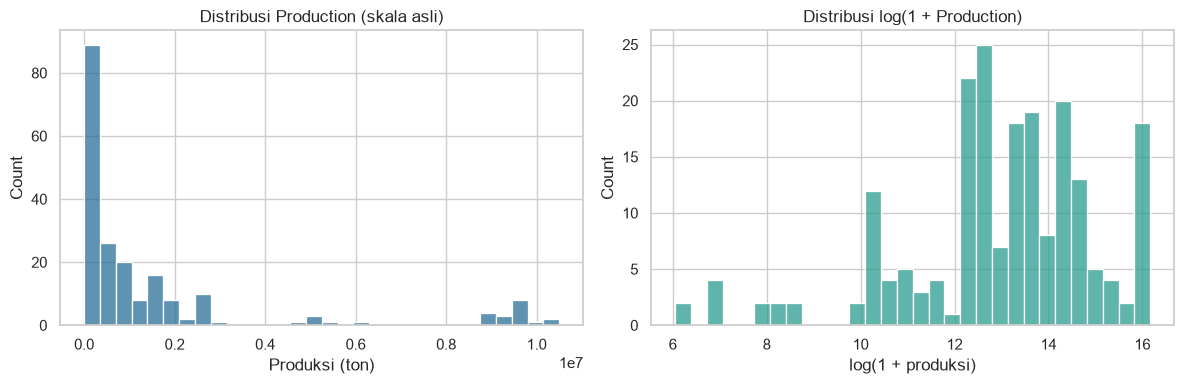

Rata-rata : 1,623,743 ton
Median    : 531,098 ton
Skewness  : 2.31


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Production"], bins=30, ax=ax[0], color="#2a6f97")
ax[0].set_title("Distribusi Production (skala asli)")
ax[0].set_xlabel("Produksi (ton)")
sns.histplot(np.log1p(df["Production"]), bins=30, ax=ax[1], color="#2a9d8f")
ax[1].set_title("Distribusi log(1 + Production)")
ax[1].set_xlabel("log(1 + produksi)")
plt.tight_layout()
plt.show()

print(f"Rata-rata : {df['Production'].mean():,.0f} ton")
print(f"Median    : {df['Production'].median():,.0f} ton")
print(f"Skewness  : {df['Production'].skew():.2f}")

**Interpretasi:** Produksi sangat condong ke kanan: rata-rata jauh di atas median, artinya mayoritas provinsi berproduksi kecil dan hanya segelintir provinsi lumbung padi yang berproduksi sangat besar. Pada skala logaritma bentuknya jauh lebih seimbang (panel kanan), sehingga skala asli dan skala log perlu dibedakan saat membaca error model.

### Grafik 2: distribusi fitur

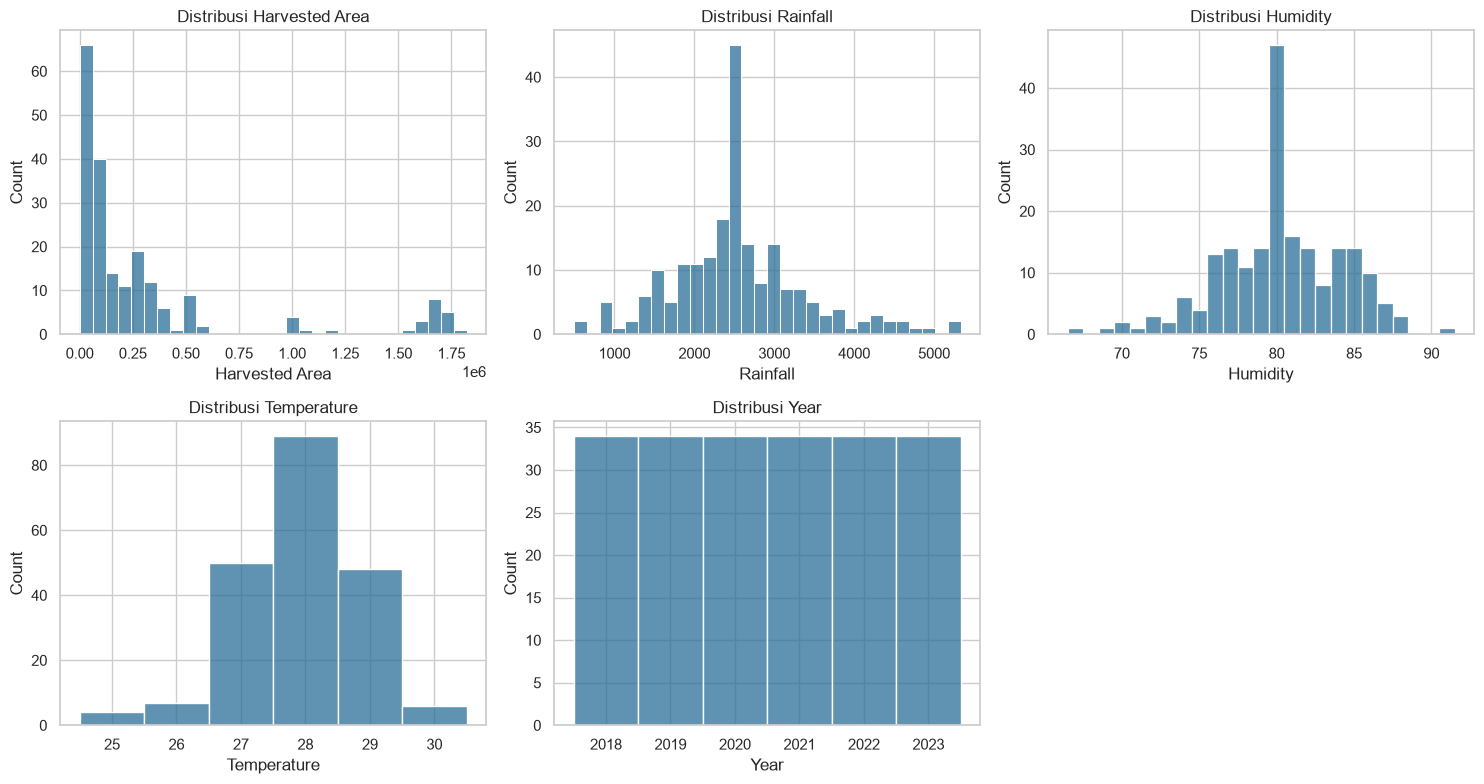

In [5]:
fitur_num = ["Harvested Area", "Rainfall", "Humidity", "Temperature", "Year"]
diskret = {"Humidity", "Temperature", "Year"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, kolom in zip(axes, fitur_num):
    if kolom in diskret:
        sns.histplot(df[kolom], discrete=True, ax=ax, color="#2a6f97")
    else:
        sns.histplot(df[kolom], bins=30, ax=ax, color="#2a6f97")
    ax.set_title(f"Distribusi {kolom}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Interpretasi:** Luas panen condong ke kanan seperti produksi, sedangkan kelembaban dan suhu terkumpul pada rentang sempit dan hanya bernilai bilangan bulat (resolusi rendah). Tahun tersebar merata karena setiap provinsi memiliki enam tahun data.

### Grafik 3: hubungan fitur dengan target

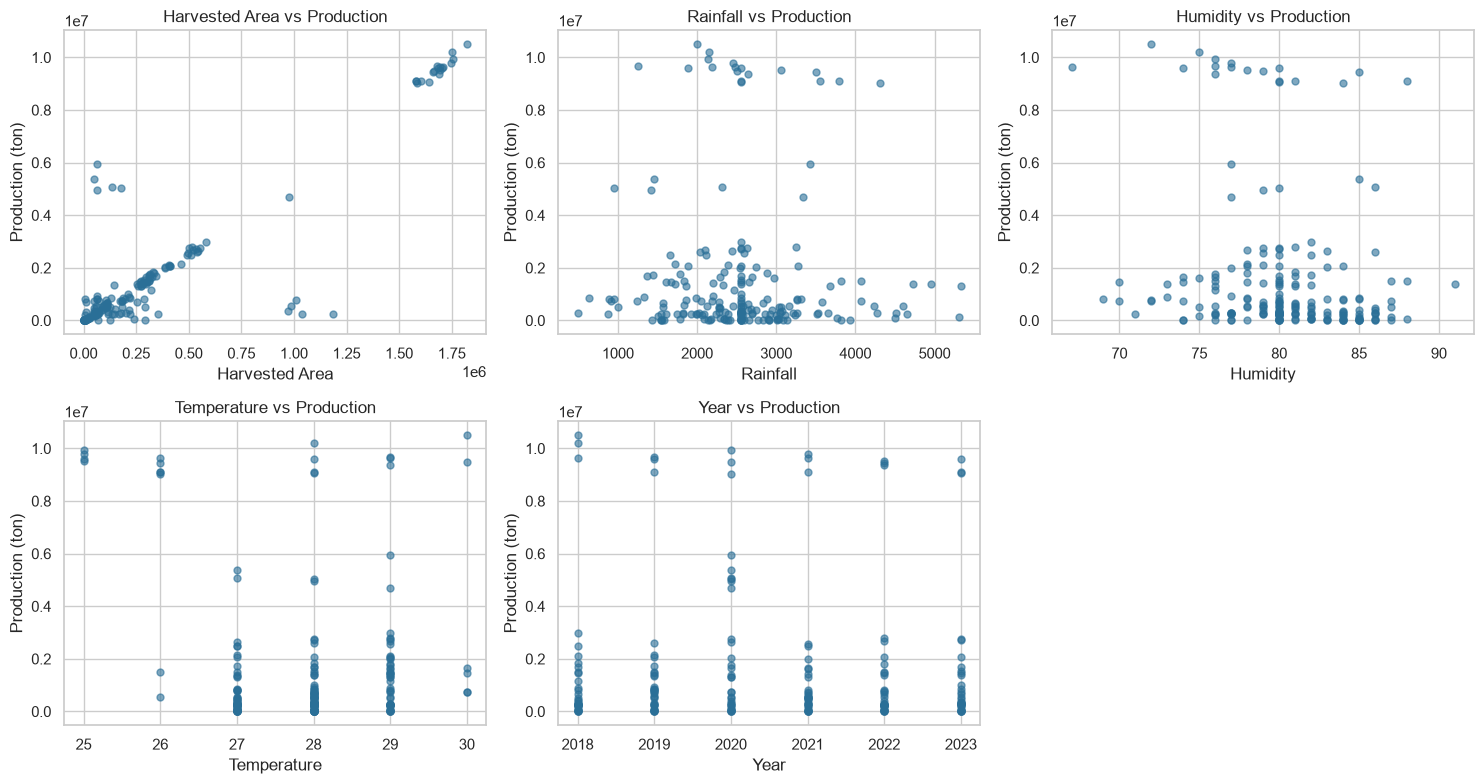

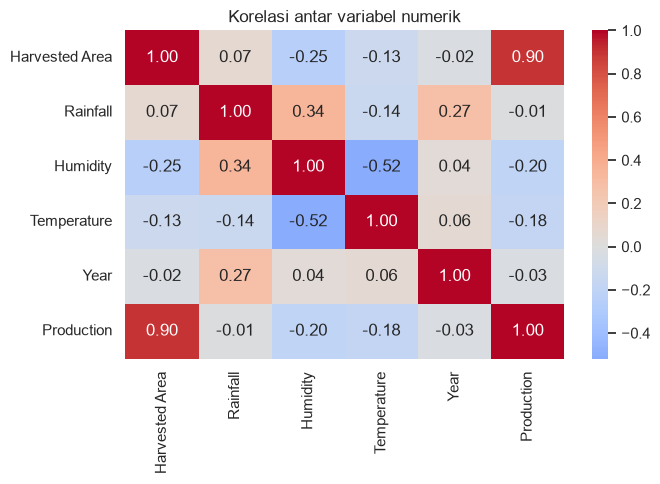

Korelasi tiap fitur dengan Production:
Harvested Area    0.903
Rainfall         -0.013
Year             -0.029
Temperature      -0.179
Humidity         -0.200
Name: Production, dtype: float64


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, kolom in zip(axes, fitur_num):
    ax.scatter(df[kolom], df["Production"], alpha=0.6, s=25, color="#2a6f97")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Production (ton)")
    ax.set_title(f"{kolom} vs Production")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

korelasi = df[fitur_num + ["Production"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar variabel numerik")
plt.tight_layout()
plt.show()

print("Korelasi tiap fitur dengan Production:")
print(korelasi["Production"].drop("Production").sort_values(ascending=False).round(3))

**Interpretasi:** Luas panen tampak membentuk pola menaik yang rapat terhadap produksi, sedangkan curah hujan, kelembaban, dan suhu menyebar tanpa pola garis lurus yang jelas. Besaran korelasi pastinya tercetak di bawah grafik.

### Pemeriksaan nilai curah hujan yang rendah
Nilai minimum Rainfall (490 mm) terlihat rendah untuk Indonesia, jadi saya lihat baris-barisnya.

In [7]:
display(df[df["Rainfall"] < 1000].sort_values("Rainfall"))

,Province,Year,Harvested Area,Production,Rainfall,Humidity,Temperature
150,Sulawesi Tengah,2018,201279,277776,490,79,28
151,Sulawesi Tengah,2019,186100,844904,637,78,28
154,Sulawesi Tengah,2022,168993,231211,879,80,27
175,Sulawesi Barat,2019,62581,812948,885,78,28
169,Gorontalo,2019,49010,744409,910,80,28
152,Sulawesi Tengah,2020,178067,5054167,954,80,28
109,Nusa Tenggara Timur,2019,198867,811724,955,69,29


### Keputusan saya (Tahap 2)
Saya memakai tiga kelompok grafik sesuai ketentuan jalur B: distribusi target, distribusi fitur, dan hubungan fitur dengan target. Karena produksi dan luas panen sangat condong ke kanan, saya menampilkan juga skala log untuk target agar bentuk distribusinya terbaca. Baris dengan curah hujan rendah saya tampilkan untuk diperiksa; saya tidak mengubahnya karena tidak ada bukti bahwa itu salah input (bisa saja wilayah kering seperti Nusa Tenggara), tetapi saya mencatatnya sebagai keterbatasan.

## 3. Pra-pemrosesan Data

In [8]:
print("== Missing value ==")
print(df.isna().sum())
print("\n== Duplikat ==")
print("Baris duplikat:", df.duplicated().sum())

print("\n== Konsistensi kategori (Province) ==")
prov = df["Province"]
print("Jumlah provinsi unik:", prov.nunique())
print("Nama dengan spasi berlebih:", (prov != prov.str.strip()).sum())
print("Jumlah unik setelah strip + huruf kecil:", prov.str.strip().str.lower().nunique())
print("Sebaran jumlah baris per provinsi:", df.groupby("Province").size().value_counts().to_dict())

== Missing value ==
Province          0
Year              0
Harvested Area    0
Production        0
Rainfall          0
Humidity          0
Temperature       0
dtype: int64

== Duplikat ==
Baris duplikat: 0

== Konsistensi kategori (Province) ==
Jumlah provinsi unik: 34
Nama dengan spasi berlebih: 0
Jumlah unik setelah strip + huruf kecil: 34
Sebaran jumlah baris per provinsi: {6: 34}


,batas_bawah,batas_atas,jumlah_outlier,persen
kolom,,,,
Harvested Area,"-338,388.250","703,351.750",24,11.765
Rainfall,779.125,"4,266.125",12,5.882
Humidity,70.500,90.500,5,2.451
Temperature,24.000,32.000,0,0.000
Year,"2,014.500","2,026.500",0,0.000
Production,"-1,766,313.250","3,557,270.750",24,11.765



Provinsi penyumbang outlier Production (jumlah baris):
Province
Jawa Barat           6
Jawa Tengah          6
Jawa Timur           6
Sulawesi Utara       1
Sulawesi Tengah      1
Sulawesi Selatan     1
Sulawesi Tenggara    1
Gorontalo            1
Sulawesi Barat       1
Name: count, dtype: int64


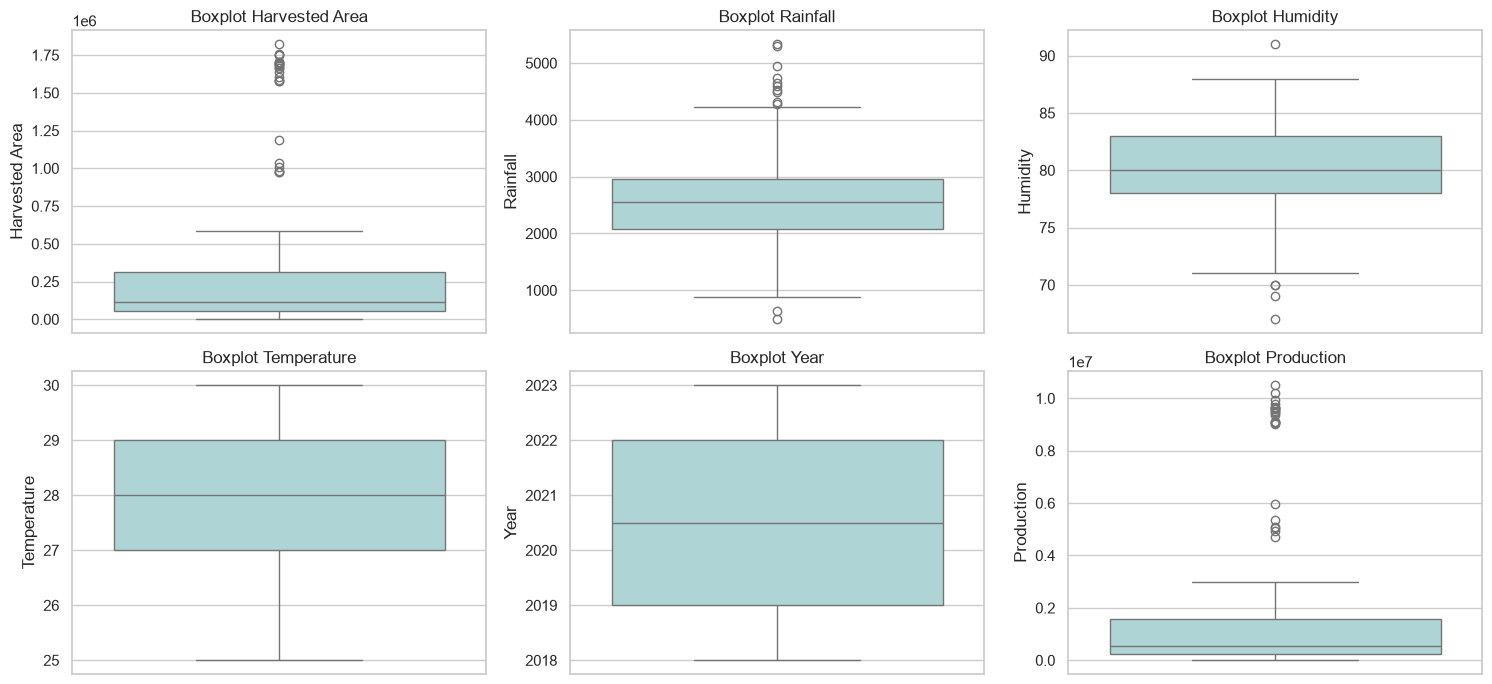

In [9]:
def outlier_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (s < batas_bawah) | (s > batas_atas), batas_bawah, batas_atas

baris = []
for kolom in fitur_num + ["Production"]:
    mask, bb, ba = outlier_iqr(df[kolom])
    baris.append({"kolom": kolom, "batas_bawah": bb, "batas_atas": ba,
                  "jumlah_outlier": int(mask.sum()), "persen": 100 * mask.mean()})
tabel_outlier = pd.DataFrame(baris).set_index("kolom")
display(tabel_outlier)

mask_prod, _, _ = outlier_iqr(df["Production"])
print("\nProvinsi penyumbang outlier Production (jumlah baris):")
print(df.loc[mask_prod, "Province"].value_counts())

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.ravel()
for ax, kolom in zip(axes, fitur_num + ["Production"]):
    sns.boxplot(y=df[kolom], ax=ax, color="#a8dadc")
    ax.set_title(f"Boxplot {kolom}")
plt.tight_layout()
plt.show()

In [10]:
TARGET = "Production"
NUM = ["Harvested Area", "Rainfall", "Humidity", "Temperature", "Year"]
CAT = ["Province"]

X = df[NUM + CAT]
y = df[TARGET]

# Pembagian data DULU, sebelum scaler/encoder di-fit (regresi: tanpa stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)

print("Data latih :", X_train.shape, "| Data uji:", X_test.shape)


def buat_model(estimator, num_cols, cat_cols=None):
    """Pipeline: scaling (dan one-hot bila perlu) di-fit hanya pada data latih."""
    langkah = [("num", StandardScaler(), num_cols)]
    if cat_cols:
        langkah.append(("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols))
    return Pipeline([("prep", ColumnTransformer(langkah)), ("model", estimator)])

Data latih : (163, 6) | Data uji: (41, 6)


### Keputusan saya (Tahap 3)
- **Missing value dan duplikat:** tidak ada, sehingga tidak ada imputasi atau penghapusan baris.
- **Kategori tidak konsisten:** nama provinsi sudah konsisten (34 nama unik, tanpa spasi berlebih atau variasi huruf), jadi tidak ada yang perlu diseragamkan.
- **Outlier (IQR):** produksi dan luas panen memiliki banyak outlier menurut IQR. Saya **tidak membuangnya**, karena outlier tersebut adalah provinsi lumbung padi (misalnya di Jawa) yang nilainya valid; membuangnya akan menghilangkan provinsi terpenting bagi pengguna. Konsekuensinya, regresi linear peka terhadap titik besar ini, sehingga saya periksa residualnya di Tahap 5.
- **Pembagian data:** 80% latih dan 20% uji dengan `random_state=SEED`, **sebelum** scaler dan encoder di-fit, tanpa `stratify` karena targetnya numerik.
- **Scaling:** `StandardScaler` di dalam `Pipeline` sehingga hanya belajar dari data latih (tidak ada kebocoran data). Scaling tidak mengubah prediksi regresi linear biasa, tetapi membuat koefisien terstandar bisa dibandingkan antarfitur.
- **Encoding:** `Province` hanya di-one-hot pada model tambahan. Model berganda utama memakai fitur numerik saja, karena 33 kolom dummy untuk sekitar 163 baris latih berisiko overfitting dan tujuan utama saya melihat pengaruh luas panen dan iklim. Keputusan ini saya uji dengan CV di Tahap 4.

## 4. Pemodelan
Tiga model wajib dibandingkan dengan 5-fold cross-validation **pada data latih saja**: DummyRegressor (baseline), regresi linear sederhana (1 fitur paling berkorelasi dengan target), dan regresi linear berganda. Satu model tambahan (berganda + provinsi) dipakai untuk menguji keputusan encoding.

In [11]:
# Fitur regresi sederhana dipilih dari korelasi pada DATA LATIH (bukan seluruh data)
korelasi_latih = X_train[NUM].corrwith(y_train)
print("Korelasi fitur dengan target (data latih):")
print(korelasi_latih.round(3).sort_values(ascending=False))

fitur_sederhana = korelasi_latih.abs().idxmax()
print("\nFitur untuk regresi sederhana:", fitur_sederhana)

nama_dummy = "Dummy (rata-rata)"
nama_sederhana = f"Regresi sederhana ({fitur_sederhana})"
nama_berganda = "Regresi berganda (5 fitur numerik)"
nama_tambahan = "Berganda + Province (tambahan)"

models = {
    nama_dummy: buat_model(DummyRegressor(strategy="mean"), NUM),
    nama_sederhana: buat_model(LinearRegression(), [fitur_sederhana]),
    nama_berganda: buat_model(LinearRegression(), NUM),
    nama_tambahan: buat_model(LinearRegression(), NUM, CAT),
}

Korelasi fitur dengan target (data latih):
Harvested Area    0.889
Rainfall          0.025
Year             -0.002
Humidity         -0.178
Temperature      -0.190
dtype: float64

Fitur untuk regresi sederhana: Harvested Area


,CV MAE (ton),std MAE,CV RMSE (ton),CV R2,std R2
Dummy (rata-rata),"1,888,178.683","354,430.906","2,729,519.476",-0.032,0.028
Regresi sederhana (Harvested Area),"563,414.580","204,698.417","1,212,084.103",0.718,0.230
Regresi berganda (5 fitur numerik),"680,669.441","136,479.781","1,228,901.867",0.725,0.204
Berganda + Province (tambahan),"515,310.829","113,541.056","1,040,863.096",0.812,0.110


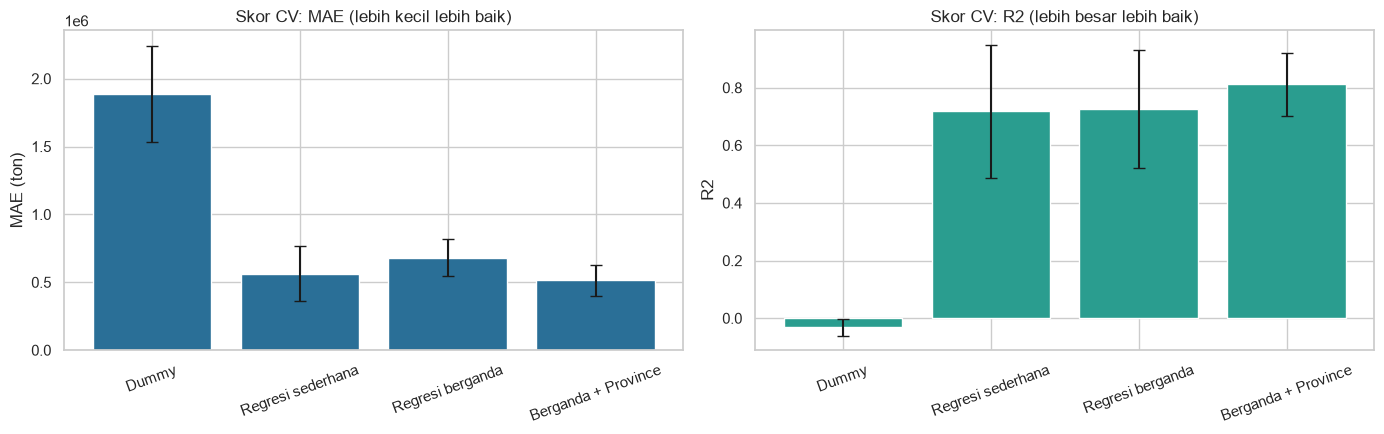

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

hasil = {}
for nama, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    hasil[nama] = {
        "CV MAE (ton)": -r["test_MAE"].mean(),
        "std MAE": r["test_MAE"].std(),
        "CV RMSE (ton)": -r["test_RMSE"].mean(),
        "CV R2": r["test_R2"].mean(),
        "std R2": r["test_R2"].std(),
    }
tabel_cv = pd.DataFrame(hasil).T
display(tabel_cv)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
nama_pendek = [n.split(" (")[0] for n in tabel_cv.index]
ax[0].bar(nama_pendek, tabel_cv["CV MAE (ton)"], yerr=tabel_cv["std MAE"], capsize=4, color="#2a6f97")
ax[0].set_title("Skor CV: MAE (lebih kecil lebih baik)")
ax[0].set_ylabel("MAE (ton)")
ax[1].bar(nama_pendek, tabel_cv["CV R2"], yerr=tabel_cv["std R2"], capsize=4, color="#2a9d8f")
ax[1].set_title("Skor CV: R2 (lebih besar lebih baik)")
ax[1].set_ylabel("R2")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Keputusan saya (Tahap 4)
- Fitur regresi sederhana dipilih otomatis dari korelasi absolut tertinggi terhadap target **pada data latih**, supaya data uji tidak ikut memengaruhi pilihan.
- Cross-validation memakai `KFold(n_splits=5, shuffle=True, random_state=SEED)` pada data latih, sesuai ketentuan jalur B. Data uji tidak disentuh sampai Tahap 5.
- `DummyRegressor(strategy="mean")` selalu menebak rata-rata produksi data latih; model regresi baru layak dipakai jika skornya jelas mengalahkan baseline ini.
- Model "Berganda + Province" saya sertakan hanya untuk menjawab pertanyaan apakah one-hot provinsi memperbaiki skor CV. Pilihan model utama saya tetap di antara tiga model wajib, dengan membaca tabel CV di atas.

## 5. Evaluasi dan Interpretasi
Setiap model di-fit pada seluruh data latih lalu diuji **satu kali** pada data uji.

In [13]:
def hitung_metrik(y_asli, y_prediksi):
    return {"MAE": mean_absolute_error(y_asli, y_prediksi),
            "RMSE": np.sqrt(mean_squared_error(y_asli, y_prediksi)),
            "R2": r2_score(y_asli, y_prediksi)}

baris = []
prediksi_uji = {}
for nama, model in models.items():
    model.fit(X_train, y_train)
    p_latih, p_uji = model.predict(X_train), model.predict(X_test)
    prediksi_uji[nama] = p_uji
    m_latih, m_uji = hitung_metrik(y_train, p_latih), hitung_metrik(y_test, p_uji)
    baris.append({"Model": nama,
                  "MAE latih": m_latih["MAE"], "MAE uji": m_uji["MAE"],
                  "RMSE uji": m_uji["RMSE"],
                  "R2 latih": m_latih["R2"], "R2 uji": m_uji["R2"],
                  "Selisih R2 (latih - uji)": m_latih["R2"] - m_uji["R2"]})
tabel_eval = pd.DataFrame(baris).set_index("Model")
display(tabel_eval)

,MAE latih,MAE uji,RMSE uji,R2 latih,R2 uji,Selisih R2 (latih - uji)
Model,,,,,,
Dummy (rata-rata),"1,883,878.406","1,589,531.775","2,235,481.724",0.000,-0.079,0.079
Regresi sederhana (Harvested Area),"552,836.410","217,028.039","344,867.194",0.790,0.974,-0.184
Regresi berganda (5 fitur numerik),"635,713.127","320,122.698","459,763.006",0.806,0.954,-0.149
Berganda + Province (tambahan),"361,253.689","434,346.539","852,493.531",0.923,0.843,0.080


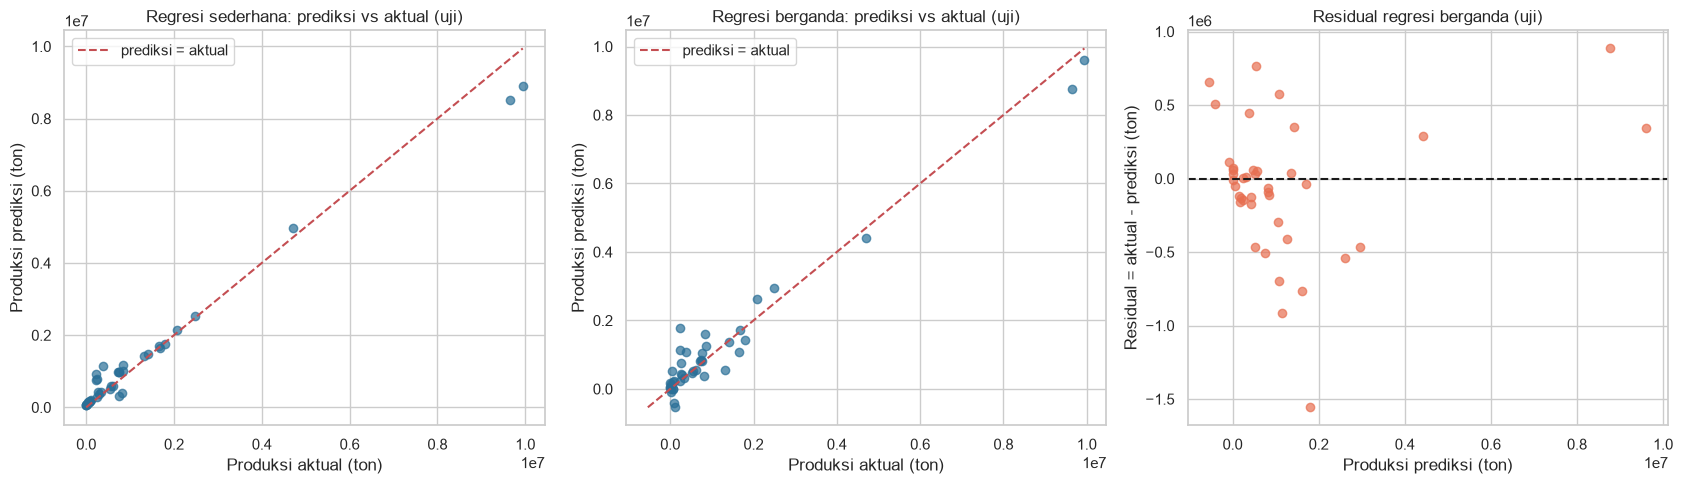

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, nama in zip(axes[:2], [nama_sederhana, nama_berganda]):
    ax.scatter(y_test, prediksi_uji[nama], alpha=0.7, color="#2a6f97")
    batas = [min(y_test.min(), prediksi_uji[nama].min()), max(y_test.max(), prediksi_uji[nama].max())]
    ax.plot(batas, batas, "r--", label="prediksi = aktual")
    ax.set_xlabel("Produksi aktual (ton)")
    ax.set_ylabel("Produksi prediksi (ton)")
    ax.set_title(nama.split(" (")[0] + ": prediksi vs aktual (uji)")
    ax.legend()

residual = y_test - prediksi_uji[nama_berganda]
axes[2].scatter(prediksi_uji[nama_berganda], residual, alpha=0.7, color="#e76f51")
axes[2].axhline(0, color="k", linestyle="--")
axes[2].set_xlabel("Produksi prediksi (ton)")
axes[2].set_ylabel("Residual = aktual - prediksi (ton)")
axes[2].set_title("Residual regresi berganda (uji)")
plt.tight_layout()
plt.show()

In [15]:
# Tafsir MAE dalam satuan target
mae_uji = tabel_eval.loc[nama_berganda, "MAE uji"]
median_prod = y.median()
print(f"MAE uji regresi berganda = {mae_uji:,.0f} ton.")
print(f"Artinya rata-rata prediksi meleset sekitar {mae_uji:,.0f} ton, "
      f"atau {mae_uji / median_prod:.0%} dari produksi median provinsi ({median_prod:,.0f} ton).")

# Arti koefisien model berganda
prep = models[nama_berganda].named_steps["prep"]
lin = models[nama_berganda].named_steps["model"]
skala = prep.named_transformers_["num"].scale_

tabel_koef = pd.DataFrame({
    "Koefisien terstandar": lin.coef_,
    "Koefisien satuan asli (ton per 1 satuan fitur)": lin.coef_ / skala,
}, index=NUM)
display(tabel_koef)

k_luas = tabel_koef.loc["Harvested Area", "Koefisien satuan asli (ton per 1 satuan fitur)"]
print(f"\nContoh tafsir: dengan fitur lain tetap, setiap tambahan 1 ha luas panen "
      f"berkaitan dengan perubahan produksi sebesar {k_luas:,.2f} ton.")

MAE uji regresi berganda = 320,123 ton.
Artinya rata-rata prediksi meleset sekitar 320,123 ton, atau 60% dari produksi median provinsi (531,098 ton).


,Koefisien terstandar,Koefisien satuan asli (ton per 1 satuan fitur)
Harvested Area,"2,508,387.015",5.117
Rainfall,"-314,728.135",-392.779
Humidity,"98,925.779","24,915.279"
Temperature,"-179,204.205","-188,089.761"
Year,"68,888.985","40,040.461"



Contoh tafsir: dengan fitur lain tetap, setiap tambahan 1 ha luas panen berkaitan dengan perubahan produksi sebesar 5.12 ton.


In [16]:
# Pemeriksaan tambahan: apakah skor CV terlalu optimis karena provinsi yang sama muncul berkali-kali?
# GroupKFold menahan seluruh baris satu provinsi di fold yang sama (deterministik, tanpa random_state).
grup_latih = X_train["Province"]
gkf = GroupKFold(n_splits=5)

baris = []
for nama in [nama_dummy, nama_sederhana, nama_berganda]:
    skor_kfold = cross_val_score(models[nama], X_train, y_train, cv=cv, scoring="r2")
    skor_grup = cross_val_score(models[nama], X_train, y_train, cv=gkf, groups=grup_latih, scoring="r2")
    baris.append({"Model": nama, "R2 KFold biasa": skor_kfold.mean(), "R2 GroupKFold (per provinsi)": skor_grup.mean()})
display(pd.DataFrame(baris).set_index("Model"))

,R2 KFold biasa,R2 GroupKFold (per provinsi)
Model,,
Dummy (rata-rata),-0.032,-0.988
Regresi sederhana (Harvested Area),0.718,0.553
Regresi berganda (5 fitur numerik),0.725,0.581


In [17]:
# Contoh konkret untuk presentasi: provinsi Bali
model_b = models[nama_berganda]
bali = df[df["Province"] == "Bali"].copy()
bali["Prediksi"] = model_b.predict(bali[NUM + CAT])
bali["Selisih (aktual - prediksi)"] = bali["Production"] - bali["Prediksi"]
bali["Masuk data uji?"] = bali.index.isin(X_test.index)
display(bali[["Year", "Harvested Area", "Production", "Prediksi", "Selisih (aktual - prediksi)", "Masuk data uji?"]])

,Year,Harvested Area,Production,Prediksi,Selisih (aktual - prediksi),Masuk data uji?
96,2018,110978,667069,"873,274.943","-206,205.943",False
97,2019,95319,579321,"700,257.060","-120,936.060",False
98,2020,90981,532168,"474,917.202","57,250.798",True
99,2021,105201,618911,"565,334.708","53,576.292",True
100,2022,112321,680602,"566,395.566","114,206.434",False
101,2023,110670,668612,"682,657.608","-14,045.608",False


### Keputusan saya (Tahap 5)
- Setiap model diuji tepat satu kali pada data uji, setelah dipilih lewat CV pada data latih, sehingga data uji tidak dipakai untuk memilih model.
- MAE saya tafsirkan dalam ton dan saya bandingkan dengan median produksi, karena produksi sangat condong ke kanan sehingga MAE dalam ton saja sulit dinilai besar-kecilnya.
- Untuk overfitting saya membaca kolom "Selisih R2 (latih - uji)" pada tabel perbandingan: selisih kecil berarti model tidak menghafal data latih.
- Koefisien berganda saya tampilkan dalam dua bentuk: terstandar (untuk membandingkan kekuatan antarfitur) dan satuan asli (untuk tafsir "ton per 1 satuan"). Tafsir ini bersifat asosiasi, bukan sebab-akibat, dan hanya berlaku bila fitur lain dianggap tetap.
- Pemeriksaan `GroupKFold` saya tambahkan karena provinsi yang sama muncul enam kali; bila skor R2-nya jauh lebih rendah daripada `KFold` biasa, berarti skor CV biasa terlalu optimis. Ketentuan UTS meminta `KFold`, jadi `KFold` tetap menjadi dasar pemilihan model dan `GroupKFold` hanya pemeriksaan tambahan.
- Plot residual saya pakai untuk melihat apakah kesalahan membesar pada provinsi berproduksi besar (pola corong), yang melanggar asumsi varians konstan regresi linear.

## 6. Kesimpulan

In [18]:
mae_dummy_cv = tabel_cv.loc[nama_dummy, "CV MAE (ton)"]
r2_dummy_cv = tabel_cv.loc[nama_dummy, "CV R2"]

# Model dipilih di antara dua model regresi wajib berdasarkan CV MAE terkecil
terbaik = tabel_cv.loc[[nama_sederhana, nama_berganda], "CV MAE (ton)"].idxmin()
mae_cv = tabel_cv.loc[terbaik, "CV MAE (ton)"]
r2_cv = tabel_cv.loc[terbaik, "CV R2"]
mae_uji_t = tabel_eval.loc[terbaik, "MAE uji"]
r2_uji_t = tabel_eval.loc[terbaik, "R2 uji"]
mae_uji_d = tabel_eval.loc[nama_dummy, "MAE uji"]
selisih_r2 = tabel_eval.loc[terbaik, "Selisih R2 (latih - uji)"]

penurunan_cv = 1 - mae_cv / mae_dummy_cv
penurunan_uji = 1 - mae_uji_t / mae_uji_d
layak = (mae_cv < mae_dummy_cv) and (r2_uji_t > 0)

print(f"Model terpilih: {terbaik}")
print(f"Layak dibanding baseline? {'YA' if layak else 'TIDAK'}\n")
print(f"Alasan 1 (CV 5-fold, data latih): MAE {mae_cv:,.0f} ton vs baseline {mae_dummy_cv:,.0f} ton "
      f"(turun {penurunan_cv:.0%}); R2 {r2_cv:.3f} vs baseline {r2_dummy_cv:.3f}.")
print(f"Alasan 2 (data uji): MAE {mae_uji_t:,.0f} ton vs baseline {mae_uji_d:,.0f} ton "
      f"(turun {penurunan_uji:.0%}); R2 uji {r2_uji_t:.3f}.")
print(f"Alasan 3 (overfitting): selisih R2 latih - uji = {selisih_r2:.3f}.")

mae_s = tabel_cv.loc[nama_sederhana, "CV MAE (ton)"]
mae_b = tabel_cv.loc[nama_berganda, "CV MAE (ton)"]
print(f"\nPerbandingan sederhana vs berganda (CV MAE): {mae_s:,.0f} vs {mae_b:,.0f} ton "
      f"-> menambah cuaca dan tahun mengubah MAE sebesar {1 - mae_b / mae_s:+.1%}.")

Model terpilih: Regresi sederhana (Harvested Area)
Layak dibanding baseline? YA

Alasan 1 (CV 5-fold, data latih): MAE 563,415 ton vs baseline 1,888,179 ton (turun 70%); R2 0.718 vs baseline -0.032.
Alasan 2 (data uji): MAE 217,028 ton vs baseline 1,589,532 ton (turun 86%); R2 uji 0.974.
Alasan 3 (overfitting): selisih R2 latih - uji = -0.184.

Perbandingan sederhana vs berganda (CV MAE): 563,415 vs 680,669 ton -> menambah cuaca dan tahun mengubah MAE sebesar -20.8%.


### Rekomendasi bagi pengguna
- Gunakan model terpilih sebagai **perkiraan awal** produksi dari luas panen yang direncanakan, misalnya untuk menyusun skenario stok dan distribusi beras sebelum angka resmi BPS terbit.
- Perlakukan hasilnya sebagai kisaran, bukan angka pasti: tafsirkan selisih prediksi dengan MAE (dalam ton) yang dilaporkan di atas, dan lebih berhati-hati pada provinsi berproduksi sangat besar atau sangat kecil.
- Bandingkan skor model sederhana dan berganda pada tabel CV. Jika tambahan variabel iklim hanya mengubah MAE sedikit, pengguna cukup memantau luas panen sebagai penentu utama.

### Keterbatasan
1. **Baris tidak independen:** setiap provinsi muncul enam kali, sehingga `KFold` biasa dapat membuat skor CV terlalu optimis (lihat hasil `GroupKFold`).
2. **Resolusi rendah:** kelembaban dan suhu hanya bilangan bulat dan merupakan agregat tahunan, sehingga variasi iklim antarprovinsi kurang tertangkap.
3. **Kualitas data:** data Desember 2023 adalah estimasi, dan ada nilai curah hujan sangat rendah (minimum 490 mm) yang tidak dapat saya verifikasi.
4. **Asumsi linear:** model mengandaikan produktivitas per hektare kira-kira tetap; kesalahan cenderung lebih besar pada provinsi besar (outlier valid yang saya pertahankan).
5. **Data kecil:** hanya 204 baris (sekitar 163 untuk latih), dan koefisien hanya menunjukkan asosiasi, bukan sebab-akibat.

### Saran perbaikan
- Menambahkan variabel yang relevan seperti irigasi, pupuk, jenis lahan, dan musim tanam.
- Memodelkan produktivitas (ton per ha) atau memakai log target agar kesalahan tidak membesar pada provinsi besar.
- Mencoba model non-linear (misalnya pohon keputusan) dan validasi berbasis waktu atau berbasis provinsi.

### Keputusan saya (Tahap 6)
Saya menilai kelayakan model dengan membandingkan CV MAE dan R2 terhadap `DummyRegressor`, lalu memastikan hasil pada data uji sejalan dan selisih R2 latih-uji kecil. Model dipilih di antara dua model regresi wajib berdasarkan CV MAE terkecil pada data latih, bukan berdasarkan data uji. Angka alasan yang saya kutip adalah angka yang tercetak pada sel kesimpulan di atas.